# Notebook 05 — Optimized Fraud Model Evaluation

## Why this version is different
The first experiment produced a nearly perfect Random Forest score. That may be possible on PaySim, but we must check whether the model relies on fields that are only known **after** a transaction is completed.

This notebook:
1. Recreates the chronological train/test split from Notebook 04.
2. Splits the original training period again into earlier training data and a later validation period.
3. Uses a manageable training sample while keeping validation and test data at their natural class prevalence.
4. Starts with **pre-transaction features only**.
5. Compares Dummy, Logistic Regression, and Random Forest.
6. Selects a decision threshold on validation data—not on the final test set.
7. Evaluates the chosen threshold once on the untouched chronological test set.

**Prediction-time assumption:** this first safe feature set assumes a decision must be made before the transaction's new balances are known. If your actual system scores transactions after balance updates, we can separately evaluate those post-transaction features as a diagnostic.

This notebook does not apply SMOTE or resampling to validation/test data.

In [1]:
from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, fbeta_score, confusion_matrix, classification_report
)

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists() and (PROJECT_ROOT.parent / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "transactions_features.csv.gz"
SPLIT_CONFIG_PATH = PROJECT_ROOT / "notebooks" / "outputs" / "split_config.json"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing feature dataset: {DATA_PATH}")
if not SPLIT_CONFIG_PATH.exists():
    raise FileNotFoundError(f"Missing split config: {SPLIT_CONFIG_PATH}")

print("Project root:", PROJECT_ROOT)
print("Feature dataset:", DATA_PATH)
print("Split config:", SPLIT_CONFIG_PATH)

Project root: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system
Feature dataset: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\data\processed\transactions_features.csv.gz
Split config: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\split_config.json


In [2]:
with open(SPLIT_CONFIG_PATH, "r", encoding="utf-8") as f:
    split_config = json.load(f)

TARGET = split_config["target_column"]
TIME_COL = split_config["time_column"]
CUTOFF_STEP = int(split_config["cutoff_step"])

df = pd.read_csv(DATA_PATH, compression="gzip")
if TARGET not in df.columns or TIME_COL not in df.columns:
    raise ValueError(f"Dataset must contain {TARGET!r} and {TIME_COL!r}.")

# Outer split: exactly reproduces Notebook 04.
outer_train = df.loc[df[TIME_COL] <= CUTOFF_STEP]
test_df = df.loc[df[TIME_COL] > CUTOFF_STEP].copy()

# Inner chronological validation split: last 20% of unique outer-training steps.
train_steps = np.sort(outer_train[TIME_COL].dropna().unique())
if len(train_steps) < 5:
    raise ValueError("Not enough unique steps to create a train/validation split.")
inner_position = int(np.floor(len(train_steps) * 0.80)) - 1
inner_position = max(0, min(inner_position, len(train_steps) - 2))
VALIDATION_CUTOFF = int(train_steps[inner_position])

train_df = outer_train.loc[outer_train[TIME_COL] <= VALIDATION_CUTOFF].copy()
valid_df = outer_train.loc[outer_train[TIME_COL] > VALIDATION_CUTOFF].copy()

assert train_df[TIME_COL].max() < valid_df[TIME_COL].min()
assert valid_df[TIME_COL].max() < test_df[TIME_COL].min()

def describe_partition(name, part):
    n = len(part)
    fraud = int(part[TARGET].sum())
    return {
        "partition": name,
        "rows": n,
        "fraud_rows": fraud,
        "normal_rows": n - fraud,
        "fraud_rate_pct": 100 * fraud / n if n else 0,
        "min_step": int(part[TIME_COL].min()),
        "max_step": int(part[TIME_COL].max())
    }

display(pd.DataFrame([
    describe_partition("training_period_before_sampling", train_df),
    describe_partition("validation_natural_prevalence", valid_df),
    describe_partition("final_test_natural_prevalence", test_df)
]))

print("Outer training cutoff:", CUTOFF_STEP)
print("Inner validation cutoff:", VALIDATION_CUTOFF)

,partition,rows,fraud_rows,normal_rows,fraud_rate_pct,min_step,max_step
0,training_period_before_sampling,6032860,5315,6027545,0.088101,1,475
1,validation_natural_prevalence,206180,1244,204936,0.603356,476,594
2,final_test_natural_prevalence,123580,1654,121926,1.338404,595,743


Outer training cutoff: 594
Inner validation cutoff: 475


## Define prediction-time-safe features

The prior model included features based on `newbalanceOrig` and `newbalanceDest`. Those are post-transaction values in this dataset. If the detector must act before the transaction completes, they are not available at prediction time and can make scores misleading.

The safe set below excludes:
- `isFraud` (the label)
- `isFlaggedFraud` (potential leakage)
- account identifiers (`nameOrig`, `nameDest`)
- `step` (only used to order the split)
- new/post-transaction balances and all features derived from them, including balance errors and balance-zero flags.

It keeps transaction type, amount, pre-transaction balances, time-derived fields, the pre-transaction amount ratio, and prior-step account activity. This is a stricter and more realistic test for pre-transaction fraud detection.

In [3]:
excluded = {
    TARGET, "isFlaggedFraud", "nameOrig", "nameDest", TIME_COL,
    "newbalanceOrig", "newbalanceDest",
    "origin_balance_error", "destination_balance_error",
    "origin_balance_error_abs", "destination_balance_error_abs",
    "origin_emptied", "destination_balance_zero"
}
feature_columns = [c for c in df.columns if c not in excluded]

# Explicitly guard against accidentally reintroducing post-transaction fields.
post_transaction_names = {
    "newbalanceOrig", "newbalanceDest",
    "origin_balance_error", "destination_balance_error",
    "origin_balance_error_abs", "destination_balance_error_abs",
    "origin_emptied", "destination_balance_zero"
}
assert not (set(feature_columns) & post_transaction_names)
assert TARGET not in feature_columns
assert "isFlaggedFraud" not in feature_columns
assert "nameOrig" not in feature_columns and "nameDest" not in feature_columns

print("Safe predictors:", feature_columns)
print("Number of predictors:", len(feature_columns))
print("Post-transaction features excluded:", sorted(post_transaction_names & set(df.columns)))

Safe predictors: ['type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'hour_of_day', 'night_flag', 'amount_to_origin_balance_ratio', 'origin_balance_was_zero', 'origin_txn_count_prior_steps']
Number of predictors: 9
Post-transaction features excluded: ['destination_balance_error', 'destination_balance_error_abs', 'destination_balance_zero', 'newbalanceDest', 'newbalanceOrig', 'origin_balance_error', 'origin_balance_error_abs', 'origin_emptied']


In [4]:
# Training-only sampling: keep all fraud rows and sample up to 20 normal rows per fraud row.
# Validation and test sets are NOT sampled.
NORMALS_PER_FRAUD = 20
RANDOM_STATE = 42

train_fraud = train_df.loc[train_df[TARGET] == 1]
train_normal = train_df.loc[train_df[TARGET] == 0]
if train_fraud.empty:
    raise ValueError("No fraud examples in the training partition.")

normal_sample_size = min(len(train_normal), len(train_fraud) * NORMALS_PER_FRAUD)
train_normal_sample = train_normal.sample(n=normal_sample_size, random_state=RANDOM_STATE)
train_sample = pd.concat([train_fraud, train_normal_sample], ignore_index=False)
train_sample = train_sample.sample(frac=1, random_state=RANDOM_STATE)

X_train = train_sample[feature_columns].copy()
y_train = train_sample[TARGET].astype("int8").copy()
X_valid = valid_df[feature_columns].copy()
y_valid = valid_df[TARGET].astype("int8").copy()
X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype("int8").copy()

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in feature_columns if c not in categorical_features]

for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_valid[col] = pd.to_numeric(X_valid[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

print(f"Training sample: {len(X_train):,} rows")
print(f"Training fraud: {int(y_train.sum()):,}; normal: {int((y_train == 0).sum()):,}")
print(f"Validation rows (natural prevalence): {len(X_valid):,}; fraud: {int(y_valid.sum()):,}")
print(f"Test rows (natural prevalence): {len(X_test):,}; fraud: {int(y_test.sum()):,}")

Training sample: 111,615 rows
Training fraud: 5,315; normal: 106,300
Validation rows (natural prevalence): 206,180; fraud: 1,244
Test rows (natural prevalence): 123,580; fraud: 1,654


C:\Users\Tanish.Ranjan\AppData\Local\Temp\ipykernel_25484\2475896748.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


In [5]:
def make_preprocessor():
    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features)
        ],
        remainder="drop"
    )

models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)": LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="liblinear",
        random_state=RANDOM_STATE
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=100,
        max_depth=14,
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
validation_scores = {}
test_scores = {}
fit_times = {}

for name, estimator in models.items():
    print("\nTraining:", name)
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("classifier", estimator)
    ])
    started = time.time()
    pipeline.fit(X_train, y_train)
    fit_times[name] = time.time() - started

    validation_scores[name] = pipeline.predict_proba(X_valid)[:, 1]
    test_scores[name] = pipeline.predict_proba(X_test)[:, 1]
    fitted_models[name] = pipeline

    print(f"Fit time: {fit_times[name]:.1f} seconds")
    print(f"Validation Average Precision: {average_precision_score(y_valid, validation_scores[name]):.6f}")

print("\nModel training complete.")


Training: Dummy (most frequent)
Fit time: 0.4 seconds
Validation Average Precision: 0.006034

Training: Logistic Regression (balanced)
Fit time: 1.2 seconds
Validation Average Precision: 0.517565

Training: Random Forest (balanced)
Fit time: 4.6 seconds
Validation Average Precision: 0.938738

Model training complete.


## Select a threshold on validation data

A 0.50 threshold is not automatically best for fraud detection. We select a threshold using the validation set only, maximizing **F2** (which weights recall more heavily than precision). We also report precision and recall so the trade-off is visible.

The selected threshold is a project choice, not a universal optimum. In a real deployment, the acceptable false-positive rate and cost of missed fraud should guide it.

In [6]:
def threshold_summary(y_true, scores, threshold):
    pred = (scores >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "average_precision": float(average_precision_score(y_true, scores)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "f2": float(fbeta_score(y_true, pred, beta=2, zero_division=0)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }

threshold_rows = []
selected_thresholds = {}

for name, scores in validation_scores.items():
    # A modest grid is adequate for this first pass and avoids expensive fine-grained searches.
    candidates = np.unique(np.concatenate([
        np.linspace(0.05, 0.95, 19),
        np.quantile(scores, [0.90, 0.95, 0.98, 0.99, 0.995, 0.999])
    ]))
    candidates = candidates[(candidates > 0) & (candidates < 1)]
    candidate_rows = [threshold_summary(y_valid, scores, t) for t in candidates]
    candidate_df = pd.DataFrame(candidate_rows)
    best_row = candidate_df.sort_values(
        ["f2", "recall", "precision"], ascending=False
    ).iloc[0].to_dict()
    selected_thresholds[name] = float(best_row["threshold"])
    threshold_rows.append({"model": name, **best_row})

threshold_df = pd.DataFrame(threshold_rows).sort_values("f2", ascending=False)
display(threshold_df)
print("Thresholds were selected on validation data only.")

,model,threshold,average_precision,precision,recall,f1,f2,tn,fp,fn,tp
2,Random Forest (balanced),0.80,0.938738,0.917431,0.884244,0.900532,0.890688,204837.0,99.0,144.0,1100.0
1,Logistic Regression (balanced),0.90,0.517565,0.363419,0.611736,0.455962,0.538190,203603.0,1333.0,483.0,761.0
0,Dummy (most frequent),0.05,0.006034,0.000000,0.000000,0.000000,0.000000,204936.0,0.0,1244.0,0.0


Thresholds were selected on validation data only.


In [7]:
# Evaluate once on the untouched chronological test set, using validation-selected thresholds.
test_rows = []
for name, scores in test_scores.items():
    threshold = selected_thresholds[name]
    row = threshold_summary(y_test, scores, threshold)
    row["model"] = name
    row["validation_selected_threshold"] = threshold
    row["fit_seconds"] = fit_times[name]
    test_rows.append(row)

test_results = pd.DataFrame(test_rows).sort_values("average_precision", ascending=False)
display(test_results)

RESULTS_PATH = OUTPUT_DIR / "optimized_baseline_test_results.csv"
VALIDATION_PATH = OUTPUT_DIR / "validation_threshold_results.csv"
test_results.to_csv(RESULTS_PATH, index=False)
threshold_df.to_csv(VALIDATION_PATH, index=False)

print("Saved test report:", RESULTS_PATH)
print("Saved validation threshold report:", VALIDATION_PATH)

,threshold,average_precision,precision,recall,f1,f2,tn,fp,fn,tp,model,validation_selected_threshold,fit_seconds
2,0.80,0.956723,0.942170,0.876663,0.908237,0.889025,121837,89,204,1450,Random Forest (balanced),0.80,4.584095
1,0.90,0.639760,0.547606,0.601572,0.573322,0.589944,121104,822,659,995,Logistic Regression (balanced),0.90,1.179516
0,0.05,0.013384,0.000000,0.000000,0.000000,0.000000,121926,0,1654,0,Dummy (most frequent),0.05,0.437553


Saved test report: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\optimized_baseline_test_results.csv
Saved validation threshold report: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\validation_threshold_results.csv


Best model by test Average Precision (reporting only): Random Forest (balanced)
Threshold chosen on validation: 0.8

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    121926
       Fraud       0.94      0.88      0.91      1654

    accuracy                           1.00    123580
   macro avg       0.97      0.94      0.95    123580
weighted avg       1.00      1.00      1.00    123580

Confusion matrix [[TN, FP], [FN, TP]]:
[[121837     89]
 [   204   1450]]


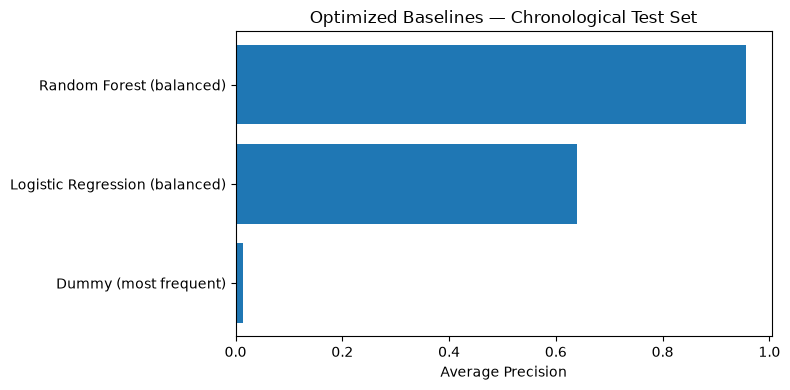

In [8]:
# Inspect detailed classification metrics for the model with the highest test Average Precision.
# This is reporting only; do not use the test result to retune the threshold.
best_name = test_results.iloc[0]["model"]
best_threshold = selected_thresholds[best_name]
best_test_pred = (test_scores[best_name] >= best_threshold).astype("int8")

print("Best model by test Average Precision (reporting only):", best_name)
print("Threshold chosen on validation:", round(best_threshold, 6))
print("\nClassification report:")
print(classification_report(y_test, best_test_pred, target_names=["Normal", "Fraud"], zero_division=0))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, best_test_pred, labels=[0, 1]))

plt.figure(figsize=(8, 4))
plot_df = test_results.sort_values("average_precision", ascending=True)
plt.barh(plot_df["model"], plot_df["average_precision"])
plt.xlabel("Average Precision")
plt.title("Optimized Baselines — Chronological Test Set")
plt.tight_layout()
plt.show()

## Optional leakage diagnostic — do not use these features by default

If you want to investigate why the original Random Forest was nearly perfect, compare it with a model that includes post-transaction balance fields. Such a model may be valid only if the business process scores after the balance updates are available. A very large score drop when removing these fields indicates that the original model depends heavily on post-transaction signals.

Do not treat the higher score as automatically better. Decide which features are genuinely available at the moment a fraud decision must be made.

In [9]:
print("NOTEBOOK 05 — OPTIMIZED BASELINE SUMMARY")
print("-" * 54)
print(f"Training sample rows: {len(X_train):,}")
print(f"Validation rows: {len(X_valid):,}")
print(f"Final test rows: {len(X_test):,}")
print("Features use pre-transaction information only, by design.")
print("Models evaluated:", ", ".join(test_results["model"].tolist()))
print("Best reported Average Precision:", best_name)
print("Test report saved:", RESULTS_PATH.exists())
print("Validation threshold report saved:", VALIDATION_PATH.exists())
print("Do not compare this score directly with the previous model without considering the feature-set change.")

NOTEBOOK 05 — OPTIMIZED BASELINE SUMMARY
------------------------------------------------------
Training sample rows: 111,615
Validation rows: 206,180
Final test rows: 123,580
Features use pre-transaction information only, by design.
Models evaluated: Random Forest (balanced), Logistic Regression (balanced), Dummy (most frequent)
Best reported Average Precision: Random Forest (balanced)
Test report saved: True
Validation threshold report saved: True
Do not compare this score directly with the previous model without considering the feature-set change.
